# SHAP analysis: what drives the XGBoost model's predictions

Task #3 of the November milestone (Final Model and Evaluation).

**Which model.** The task is to explain the best model, with PR-AUC as the main metric === XGBoost, using the test results from the README comparison table (same held-out test set for all four: 88,414 rows, 5.68% positive):

| Model | Test PR-AUC | Test ROC-AUC |
|---|---|---|
| **XGBoost** | **0.432** | **0.890** |
| Logistic Regression | 0.415 | 0.889 |
| Random Forest | 0.393 | 0.873 |
| KNN | 0.343 | 0.857 |

**What SHAP gives us.** For each person, SHAP splits the model's prediction into one contribution per feature. The contributions add up exactly: base value + sum of the SHAP values = the model's output for that person. The base value is the model's average output. XGBoost's raw output is in log-odds, so SHAP values are in log-odds, too. Rough guide for reading them: **+0.7 doubles the odds** of a "Yes" prediction and -0.7 halves them.

Everything here is computed on the held-out test set --- SHAP only describes the model that's already trained.

**Plan**
1. rebuild the original XGBoost model from `xgboost_model.ipynb` (same split, encoding and tuned hyperparameters), the model we keep
2. compute SHAP values for all 88,414 test rows
3. global feature importance ranking
4. beeswarm plot
5. dependence plots for the top features
6. individual explanations, and what the missed cases have in common
7. how much the model leans on age, sex and race/ethnicity (input for Task #4)
8. findings: top drivers & caveats

Figures, the ranking table and the model file are saved to `outputs/shap/` for the report and the slides.

** Needs `shap` and `xgboost` on top of the usual packages: `pip install shap xgboost`.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless tqdm notice from shap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
DATA_PATH = "../Data/heart_2022_with_nans.csv"
TARGET = "HadHeartAttack"
OUT_DIR = Path("../outputs/shap")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Operating threshold for sections 6-7 (individual explanations, missed cases, subgroups).
# Team decision (Nov 14): the highest cutoff that still catches 80% of heart attack cases on validation.
# Set TARGET_RECALL = None to use the old rule (best F1 on validation). Sections 2-5 don't depend on it.
TARGET_RECALL = 0.80

print("xgboost", xgb.__version__, "| shap", shap.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)

xgboost 3.2.0 | shap 0.49.1 | pandas 2.3.3 | numpy 2.2.6


### 1. Rebuild the tuned XGBoost model

Same steps as `xgboost_model.ipynb`=== drop rows with no label, split 60/20/20 stratified with seed 42, then the same encoding (Yes/No to 1/0, ordinal maps, age bracket to its lower bound, the four unordered categoricals as pandas `category` with levels from the training rows, `State` dropped) plus the five engineered columns that notebook kept.

In [2]:
with open(DATA_PATH, encoding="utf-8") as f:
    if f.readline().startswith("version https://git-lfs"):
        raise RuntimeError("Data file is a Git LFS pointer. Run `git lfs pull` first.")

df = pd.read_csv(DATA_PATH)
df = df[df[TARGET].notna()].reset_index(drop=True)
y = (df[TARGET] == "Yes").astype(int)
X_raw = df.drop(columns=[TARGET])

X_tmp, X_test_raw, y_tmp, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
del df, X_raw, X_tmp, y_tmp

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:<6}{len(part):>8,} rows   positive rate {part.mean():.2%}")

train  265,239 rows   positive rate 5.68%
val     88,414 rows   positive rate 5.68%
test    88,414 rows   positive rate 5.68%


In [3]:
YES_NO = ["PhysicalActivities", "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer",
          "HadCOPD", "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis",
          "DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
          "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands",
          "ChestScan", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12",
          "PneumoVaxEver", "HighRiskLastYear"]

ORDINAL = {
    "GeneralHealth": {"Poor": 0, "Fair": 1, "Good": 2, "Very good": 3, "Excellent": 4},
    "RemovedTeeth": {"None of them": 0, "1 to 5": 1, "6 or more, but not all": 2, "All": 3},
    "LastCheckupTime": {
        "Within past year (anytime less than 12 months ago)": 0,
        "Within past 2 years (1 year but less than 2 years ago)": 1,
        "Within past 5 years (2 years but less than 5 years ago)": 2,
        "5 or more years ago": 3},
    "SmokerStatus": {
        "Never smoked": 0, "Former smoker": 1,
        "Current smoker - now smokes some days": 2,
        "Current smoker - now smokes every day": 3},
    "ECigaretteUsage": {
        "Never used e-cigarettes in my entire life": 0, "Not at all (right now)": 1,
        "Use them some days": 2, "Use them every day": 3},
}

CAT_COLS = ["HadDiabetes", "RaceEthnicityCategory", "TetanusLast10Tdap", "CovidPos"]

CHRONIC = ["HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
           "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis"]
DISABILITY = ["DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating",
              "DifficultyWalking", "DifficultyDressingBathing", "DifficultyErrands"]


def encode(raw):
    # identical to encode(raw, engineer=True) in xgboost_model.ipynb
    X = raw.drop(columns=["State"]).copy()
    for c in YES_NO:
        X[c] = raw[c].map({"Yes": 1.0, "No": 0.0})
    X["Sex"] = raw["Sex"].map({"Male": 1.0, "Female": 0.0})
    for c, order in ORDINAL.items():
        X[c] = raw[c].map(order)
    X["AgeCategory"] = raw["AgeCategory"].str.extract(r"(\d+)", expand=False).astype(float)

    X["BMI"] = raw["BMI"].fillna(raw["WeightInKilograms"] / raw["HeightInMeters"] ** 2)
    X["chronic_count"] = X[CHRONIC].sum(axis=1)
    X["diabetes_yes"] = (raw["HadDiabetes"] == "Yes").astype(float)
    X["disability_count"] = X[DISABILITY].sum(axis=1)
    X["n_missing"] = raw.isna().sum(axis=1)
    return X


def set_categories(X, levels=None):
    X = X.copy()
    if levels is None:
        levels = {c: sorted(X[c].dropna().unique()) for c in CAT_COLS}
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c], categories=levels[c])
    return X, levels


X_train, levels = set_categories(encode(X_train_raw))
X_val, _ = set_categories(encode(X_val_raw), levels)
X_test, _ = set_categories(encode(X_test_raw), levels)
FEATURES = list(X_test.columns)
print(X_train.shape, X_val.shape, X_test.shape)

(265239, 42) (88414, 42) (88414, 42)


The hyperparameters below, are the winner of the randomized search in `xgboost_model.ipynb` (section 4), at full precision. The search doesn't need to be re-run to get them: `ParameterSampler(param_dist, n_iter=15, random_state=42)` regenerates the same 15 candidates (they match that notebook's top-5 table), and candidate 11 = winner.

Like the final model in that notebook,,, this has no `scale_pos_weight`. Its probabilities stay on the natural ~6% scale and the class imbalance is handled by the decision threshold. Early stopping on the validation set picks the number of trees.

In [4]:
BEST_PARAMS = {
    "colsample_bytree": 0.6373608964950321,
    "gamma": 1.1224868516954023,
    "learning_rate": 0.04326278471926905,
    "max_depth": 5,
    "min_child_weight": 1,
    "reg_alpha": 0.1191646709003216,
    "reg_lambda": 8.592225728587435,
    "subsample": 0.7975182385457563,
}
base_kwargs = dict(tree_method="hist", enable_categorical=True, eval_metric="auc",
                   random_state=SEED, n_jobs=-1)

model = xgb.XGBClassifier(n_estimators=2000, early_stopping_rounds=50, **BEST_PARAMS, **base_kwargs)
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
N_TREES = model.best_iteration + 1
print("trees used:", N_TREES)

# saved so Task #4 (and anyone else) can load exactly the model explained here
model.save_model(str(OUT_DIR / "xgb_final.json"))

trees used: 181


In [5]:
p_val = model.predict_proba(X_val)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD_BEST_F1 = float(thr[np.argmax(f1s)])
if TARGET_RECALL:
    THRESHOLD = float(thr[rec[:-1] >= TARGET_RECALL].max())   # highest cutoff that still reaches the target
    THRESHOLD_LABEL = f"{TARGET_RECALL:.0%} recall"
else:
    THRESHOLD, THRESHOLD_LABEL = THRESHOLD_BEST_F1, "best F1"
test_pred = (p_test >= THRESHOLD).astype(int)

print(f"operating threshold: {THRESHOLD:.3f} ({THRESHOLD_LABEL} on validation)")
print(f"best-F1 threshold, for comparison: {THRESHOLD_BEST_F1:.3f}")
print(f"test flagged  : {test_pred.mean():.1%} of people")
print(f"test ROC-AUC  : {roc_auc_score(y_test, p_test):.4f}")
print(f"test PR-AUC   : {average_precision_score(y_test, p_test):.4f}")
print(f"test F1       : {f1_score(y_test, test_pred):.4f}")
print(f"test precision: {precision_score(y_test, test_pred):.4f}")
print(f"test recall   : {recall_score(y_test, test_pred):.4f}")

operating threshold: 0.055 (80% recall on validation)
best-F1 threshold, for comparison: 0.251
test flagged  : 21.5% of people
test ROC-AUC  : 0.8906
test PR-AUC   : 0.4335
test F1       : 0.3286
test precision: 0.2077
test recall   : 0.7869


The ranking metrics match `xgboost_model.ipynb` (test PR-AUC 0.434, ROC-AUC 0.891) to abt 3 decimals. The exact # of trees and the max-F1 threshold depend on the XGBoost version: this run (XGBoost 3.2) stops at 181 trees with a threshold of 0.251, the original run stopped at 266 trees with 0.233, and XGBoost 2.1.4 stops at 307. That moves a few borderline predictions across a threshold. It doesn't change the SHAP ranking: XGBoost 3.2 and 2.1.4 give the same top 10 features in the same order, with shares within about 2 points (`HadAngina` 23.6% vs 21.4%).

Sections 6 and 7 use the our decided operating threshold: the highest cutoff that catches 80% of heart attack cases on validation (0.055 here). On the test set it catches 78.7% of cases at 20.8% precision and flags 21.5% of people.

### 2. SHAP values for the test set

With the versions used here (shap 0.49.1, XGBoost 3.2), `shap.TreeExplainer` can't load the model: it fails to parse the `base_score` format XGBoost 3 writes. XGBoost has TreeSHAP built in, though: `predict(..., pred_contribs=True)` runs the same exact algorithm (path-dependent TreeSHAP, the `TreeExplainer` default), supports the categorical columns natively, and is fast. The `shap` package is still used for every plot...

In [6]:
dtest = xgb.DMatrix(X_test, enable_categorical=True)
contribs = model.get_booster().predict(dtest, pred_contribs=True, iteration_range=(0, N_TREES))
shap_values = contribs[:, :-1]
base_value = float(contribs[0, -1])

# check: base value + SHAP values = the model's log-odds output, for every test row
margin = model.predict(X_test, output_margin=True)
print("largest additivity error:", np.abs(base_value + shap_values.sum(axis=1) - margin).max())
print(f"base value: {base_value:.3f} log-odds = {1 / (1 + np.exp(-base_value)):.1%} predicted risk")
print("SHAP matrix:", shap_values.shape)

largest additivity error: 6.198883e-06
base value: -2.836 log-odds = 5.5% predicted risk
SHAP matrix: (88414, 42)


In [7]:
# Numeric copy of the features for the plots. The four unordered categoricals have no
# low-to-high order to color by, so they're blanked out and drawn grey.
X_plot = X_test.copy()
for c in CAT_COLS:
    X_plot[c] = np.nan
X_plot = X_plot.astype(float)

sv = shap.Explanation(values=shap_values, base_values=np.full(len(X_test), base_value),
                      data=X_plot.to_numpy(), feature_names=FEATURES)

### 3. Global feature importance

Mean absolute SHAP value per feature over all 88,414 test rows: how far, on average, a feature moves a prediction away from the base value -- in either direction.

`direction` is the Spearman correlation between a feature's value and its SHAP value. Close to +1 = higher values push predicted risk up, close to -1 = they push it down, near 0 means the effect isn't monotonic. (It's blank for the four unordered categoricals). For binary features, 1 = Yes (Sex: 1 = Male).

In [8]:
def direction(col):
    if col in CAT_COLS:
        return np.nan
    x = X_test[col].astype(float).to_numpy()
    keep = ~np.isnan(x)
    return pd.Series(x[keep]).corr(pd.Series(shap_values[keep, FEATURES.index(col)]), method="spearman")


ranking = pd.DataFrame({"mean_abs_shap": np.abs(shap_values).mean(axis=0),
                        "direction": [direction(c) for c in FEATURES],
                        "gain_importance": model.feature_importances_}, index=FEATURES)
ranking = ranking.sort_values("mean_abs_shap", ascending=False)
ranking["share_%"] = 100 * ranking["mean_abs_shap"] / ranking["mean_abs_shap"].sum()
ranking["cumulative_%"] = ranking["share_%"].cumsum()
ranking["gain_rank"] = ranking["gain_importance"].rank(ascending=False).astype(int)
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking = ranking[["rank", "mean_abs_shap", "share_%", "cumulative_%", "direction", "gain_rank"]]

ranking.round(4).to_csv(OUT_DIR / "shap_global_importance.csv", index_label="feature")
ranking.head(20).round(3)

,rank,mean_abs_shap,share_%,cumulative_%,direction,gain_rank
HadAngina,1,0.723,23.649000,23.649000,0.413,1
AgeCategory,2,0.503,16.438999,40.088001,0.984,5
ChestScan,3,0.312,10.190000,50.277000,0.856,2
Sex,4,0.227,7.440000,57.717999,0.865,7
GeneralHealth,5,0.220,7.182000,64.900002,-0.944,4
RemovedTeeth,6,0.137,4.484000,69.384003,0.903,8
HadStroke,7,0.122,3.988000,73.372002,0.346,3
SmokerStatus,8,0.099,3.249000,76.620003,0.871,15
HadDiabetes,9,0.090,2.952000,79.571999,NaN,10
AlcoholDrinkers,10,0.063,2.045000,81.616997,-0.864,17


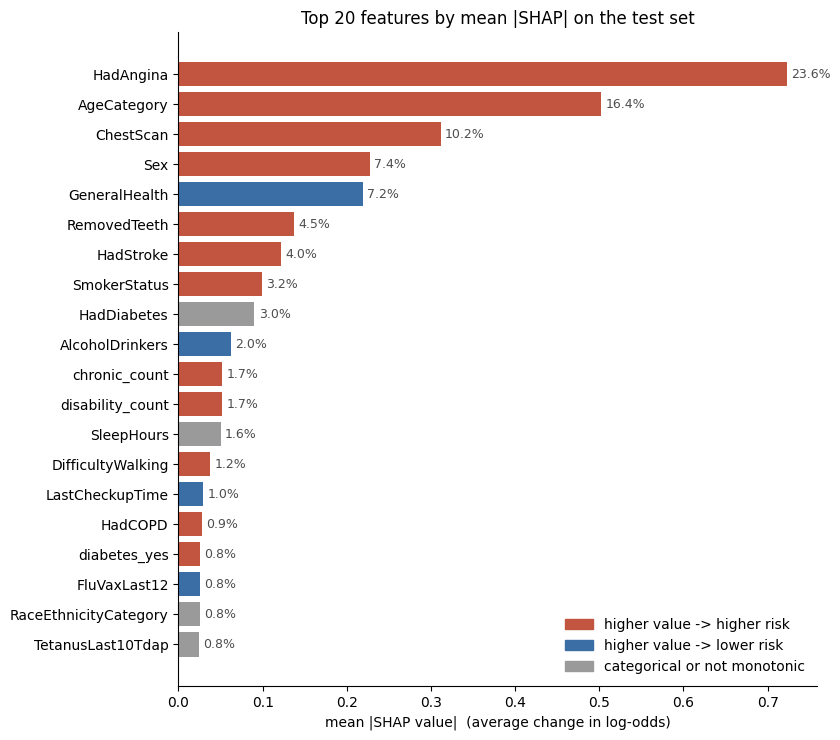

In [9]:
top = ranking.head(20).iloc[::-1]
color = np.select([top["direction"] >= 0.3, top["direction"] <= -0.3], ["#c2553f", "#3b6ea5"], "#9a9a9a")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.barh(top.index, top["mean_abs_shap"], color=color)
for i, (v, s) in enumerate(zip(top["mean_abs_shap"], top["share_%"])):
    ax.text(v + 0.005, i, f"{s:.1f}%", va="center", fontsize=9, color="0.3")
ax.set_xlabel("mean |SHAP value|  (average change in log-odds)")
ax.set_title("Top 20 features by mean |SHAP| on the test set")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#c2553f", "#3b6ea5", "#9a9a9a"]]
ax.legend(handles, ["higher value -> higher risk", "higher value -> lower risk",
                    "categorical or not monotonic"], loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_importance_bar.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the ranking.** `HadAngina` alone accounts for about a quarter of the total (23.6%), and the top 5 (`HadAngina`, `AgeCategory`, `ChestScan`, `Sex`, `GeneralHealth`) for 65%. After the top 10, the contributions get small, = the bottom 22 features add up to under 7%.

Gain importance (the chart at the end of `xgboost_model.ipynb`) ranks things differently == it puts `HadStroke` 3rd and `DifficultyWalking` 6th, where SHAP has them 7th and 14th, and it undersells `SmokerStatus` (15th by gain, 8th by SHAP) and `AlcoholDrinkers` (17th vs 10th). Gain measures how much a feature improved the splits it was used in, so a feature that only a few people have (4% report a stroke) can score high while changing few predictions. Mean |SHAP| measures how much each feature actually moves predictions across everyone, which is what "top drivers" should mean.

#### Grouped importance

Several features overlap::: `diabetes_yes` repeats `HadDiabetes == "Yes"`, `chronic_count` and `disability_count` are sums of other columns, and BMI comes from height and weight. When features share information, SHAP splits the credit between them, so each can look less important than the thing they measure together. SHAP values add up, so summing them within a group gives the group's combined effect for each person. The groups are our own judgment call.

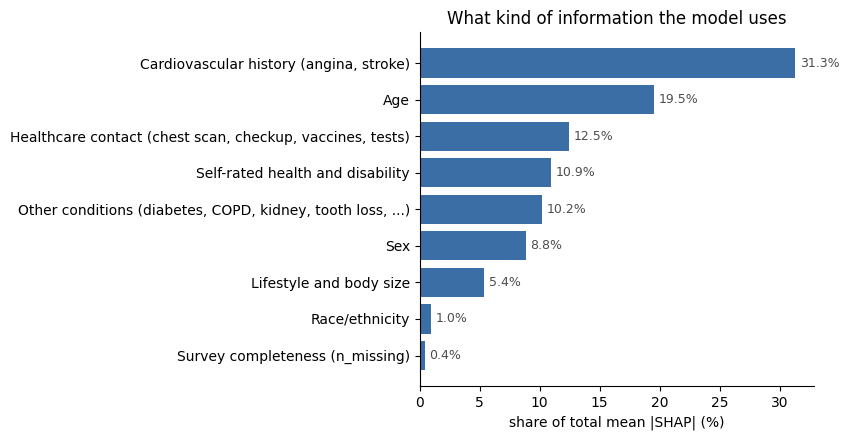

,mean_abs_shap,share_%,n_features
"Cardiovascular history (angina, stroke)",0.804,31.278,2
Age,0.503,19.542,1
"Healthcare contact (chest scan, checkup, vaccines, tests)",0.321,12.480,6
Self-rated health and disability,0.281,10.932,10
"Other conditions (diabetes, COPD, kidney, tooth loss, ...)",0.262,10.173,11
Sex,0.227,8.845,1
Lifestyle and body size,0.138,5.362,9
Race/ethnicity,0.025,0.975,1
Survey completeness (n_missing),0.011,0.413,1


In [10]:
GROUPS = {
    "Cardiovascular history (angina, stroke)": ["HadAngina", "HadStroke"],
    "Age": ["AgeCategory"],
    "Sex": ["Sex"],
    "Race/ethnicity": ["RaceEthnicityCategory"],
    "Healthcare contact (chest scan, checkup, vaccines, tests)": [
        "ChestScan", "LastCheckupTime", "FluVaxLast12", "PneumoVaxEver", "TetanusLast10Tdap", "HIVTesting"],
    "Self-rated health and disability": [
        "GeneralHealth", "PhysicalHealthDays", "MentalHealthDays", "disability_count", "DifficultyWalking",
        "DifficultyConcentrating", "DifficultyDressingBathing", "DifficultyErrands",
        "DeafOrHardOfHearing", "BlindOrVisionDifficulty"],
    "Other conditions (diabetes, COPD, kidney, tooth loss, ...)": [
        "HadDiabetes", "diabetes_yes", "chronic_count", "HadCOPD", "HadKidneyDisease", "HadArthritis",
        "HadAsthma", "HadSkinCancer", "HadDepressiveDisorder", "RemovedTeeth", "CovidPos"],
    "Lifestyle and body size": [
        "SmokerStatus", "ECigaretteUsage", "AlcoholDrinkers", "PhysicalActivities", "SleepHours",
        "BMI", "WeightInKilograms", "HeightInMeters", "HighRiskLastYear"],
    "Survey completeness (n_missing)": ["n_missing"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES), "every feature must be in exactly one group"

idx = {f: i for i, f in enumerate(FEATURES)}
group_shap = pd.DataFrame({g: shap_values[:, [idx[f] for f in fs]].sum(axis=1) for g, fs in GROUPS.items()})
grouped = group_shap.abs().mean().sort_values(ascending=False).to_frame("mean_abs_shap")
grouped["share_%"] = 100 * grouped["mean_abs_shap"] / grouped["mean_abs_shap"].sum()
grouped["n_features"] = [len(GROUPS[g]) for g in grouped.index]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
g = grouped.iloc[::-1]
ax.barh(g.index, g["share_%"], color="#3b6ea5")
for i, s in enumerate(g["share_%"]):
    ax.text(s + 0.4, i, f"{s:.1f}%", va="center", fontsize=9, color="0.3")
ax.set_xlabel("share of total mean |SHAP| (%)")
ax.set_title("What kind of information the model uses")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_grouped_importance.png", dpi=200, bbox_inches="tight")
plt.show()
grouped.round(3)

Existing CV history and age together make up about half of what the model uses (31% + 20%). Healthcare contact comes third (12%), ahead of self-rated health and the other chronic conditions. Lifestyle and body size, the factors people can change, add up to only 5%.

### 4. Beeswarm plot

1 dot per test person per feature. Horizt. position is the SHAP value (right = pushes predicted risk up). Color is the feature's value: red = high, blue = low, grey = missing or one of the four unordered categoricals. Rows are sorted by mean |SHAP|, and the last row sums up the 22 features = not shown.

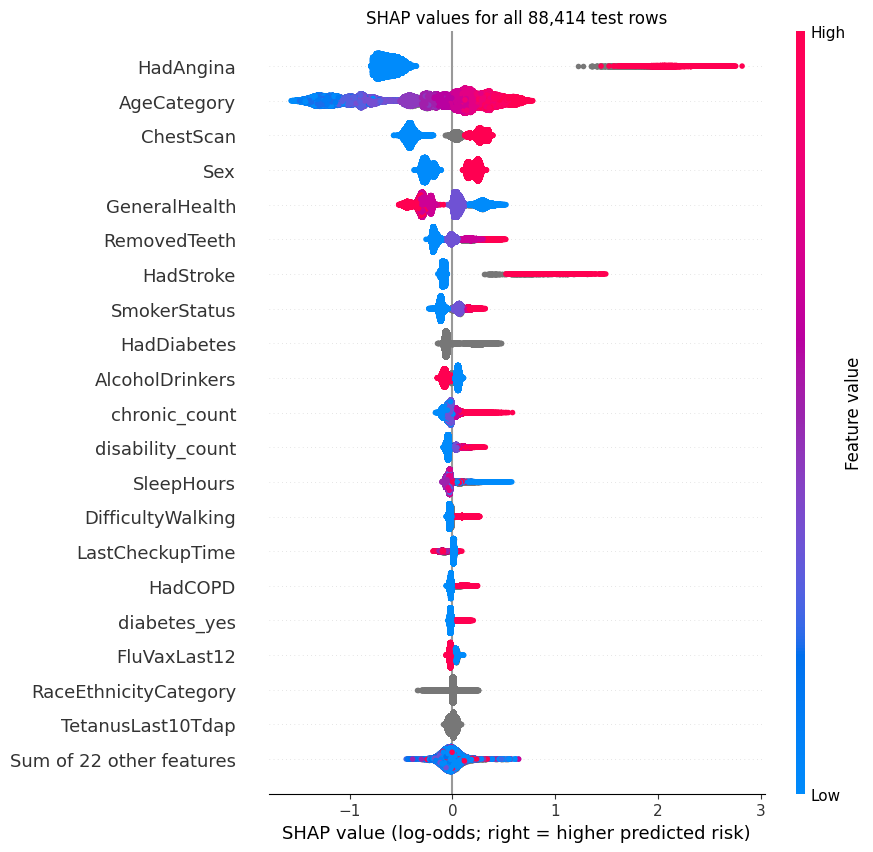

In [11]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # the blanked categorical columns are all-NaN
    shap.plots.beeswarm(sv, max_display=21, show=False, color_bar_label="Feature value")
ax = plt.gca()
ax.set_xlabel("SHAP value (log-odds; right = higher predicted risk)")
ax.set_title(f"SHAP values for all {len(X_test):,} test rows", fontsize=12)
plt.savefig(OUT_DIR / "shap_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

What stands out:
- `HadAngina` splits people into 2 clusters: about +2.1 for "Yes" and -0.6 for "No". No other feature comes close to that spread for so many people.
- `AgeCategory` is a smooth gradient from blue on the left to red on the right. The range from youngest to oldest is about 1.8 log-odds, roughly 6-fold change in the odds.
- `HadStroke` has a big effect (+0.9) for the few who report one,,, which is why it ranks below age and sex on average.
- `GeneralHealth`, `AlcoholDrinkers`, `FluVaxLast12` and `LastCheckupTime` run the other way: high values (better health, drinking, vaccinated, longer since last checkup) push predicted risk down.
- `SleepHours` has blue dots on the right: short sleep raises predicted risk. Long sleep, too.

### 5. Dependence plots

Each plot shows one feature's value (x) against its SHAP value (y) for 10,000 randomly chosen test rows (all 88k points just pile on top of each other). Discrete features get a little horizt. jitter so the dots don't stack, and missing values are drawn at the far left. Color shows a second feature: the one this feature interacts with most, taken from exact SHAP interaction values on a 2,000-row sample. Vertical spread at a single x value means the feature's effect depends on other features.

In [12]:
rng = np.random.RandomState(SEED)
inter_rows = rng.choice(len(X_test), 2000, replace=False)
inter = model.get_booster().predict(xgb.DMatrix(X_test.iloc[inter_rows], enable_categorical=True),
                                    pred_interactions=True, iteration_range=(0, N_TREES))[:, :-1, :-1]
inter_strength = np.abs(inter).mean(axis=0)
np.fill_diagonal(inter_strength, 0)


def partner(feature):
    return FEATURES[int(np.argmax(inter_strength[idx[feature]]))]


pairs = pd.DataFrame([(FEATURES[i], FEATURES[j], 2 * inter_strength[i, j])
                      for i in range(len(FEATURES)) for j in range(i + 1, len(FEATURES))],
                     columns=["feature_a", "feature_b", "mean_abs_interaction"])
print("Strongest pairwise interactions (2,000-row sample):")
pairs.sort_values("mean_abs_interaction", ascending=False).head(8).round(4).reset_index(drop=True)

Strongest pairwise interactions (2,000-row sample):


,feature_a,feature_b,mean_abs_interaction
0,HadAngina,AgeCategory,0.0889
1,Sex,AgeCategory,0.0652
2,HadAngina,ChestScan,0.0634
3,GeneralHealth,AgeCategory,0.0506
4,ChestScan,AgeCategory,0.0399
5,AgeCategory,chronic_count,0.0336
6,GeneralHealth,HadAngina,0.0304
7,RemovedTeeth,ChestScan,0.0267


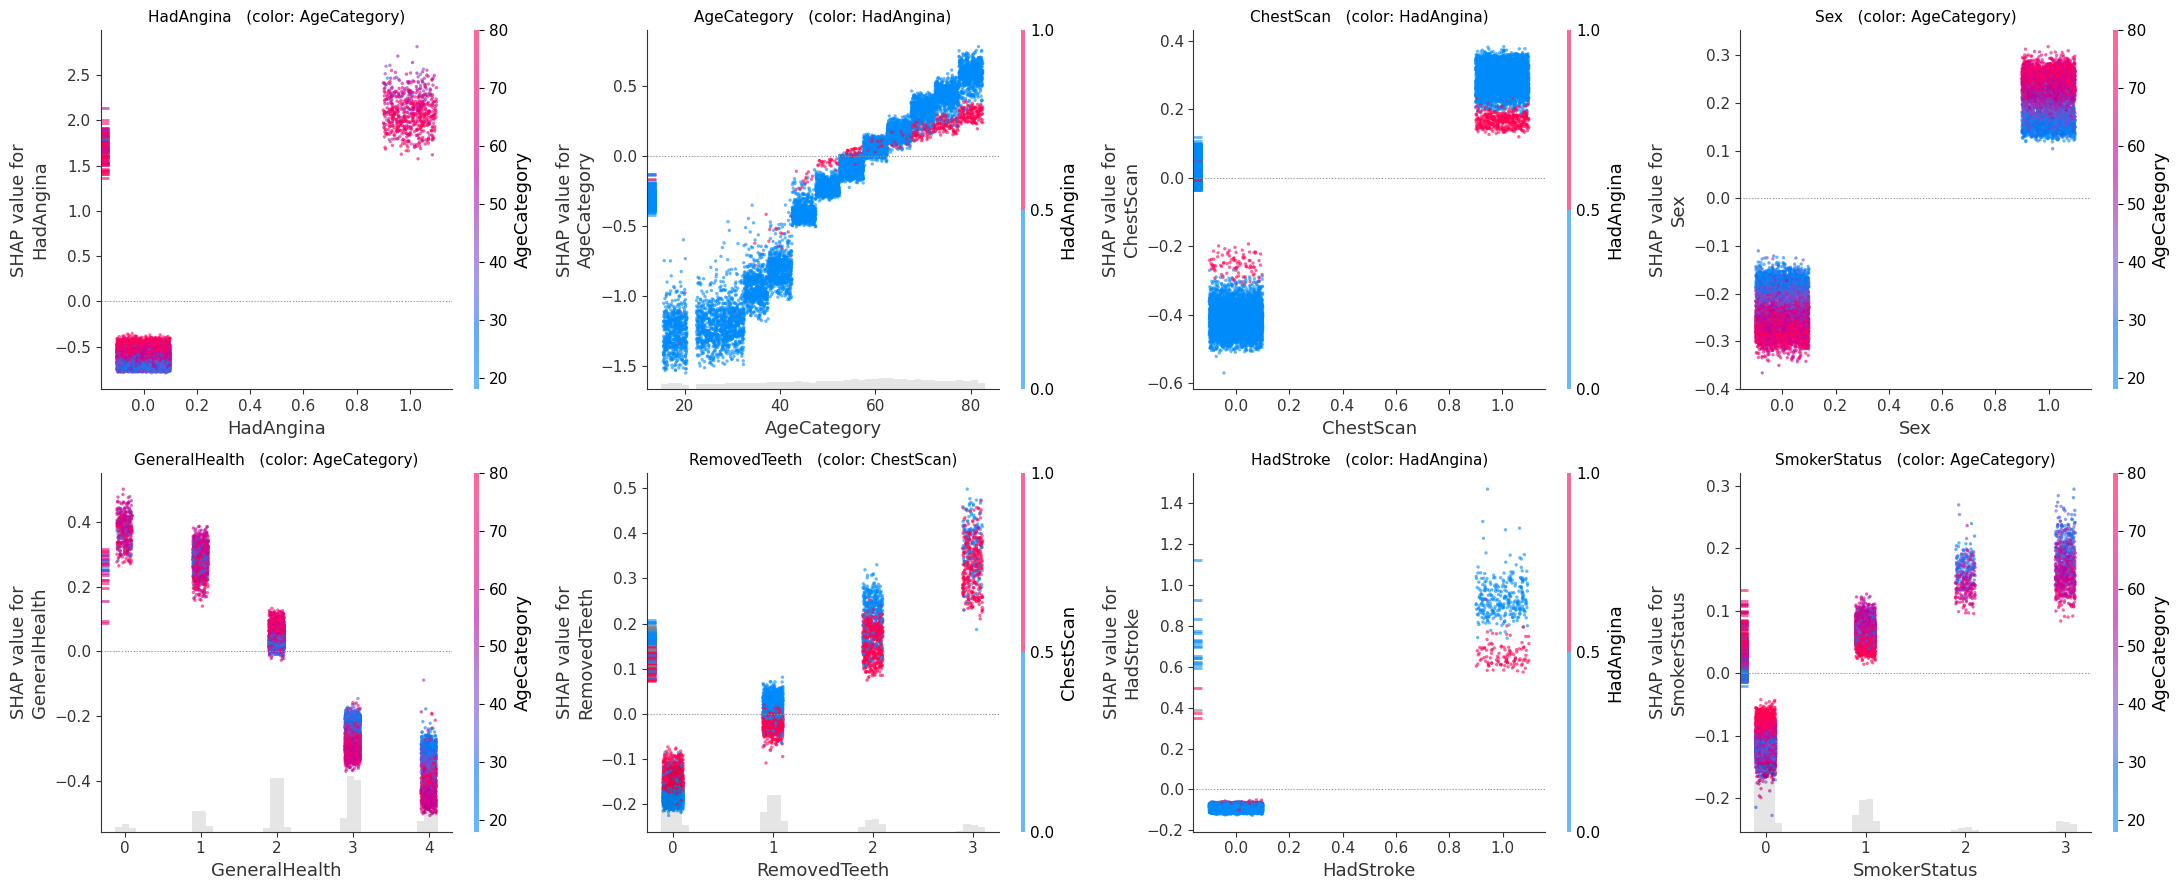

In [13]:
plot_rows = rng.choice(len(X_test), 10_000, replace=False)
sv_sample = sv[plot_rows]
np.random.seed(SEED)   # shap's jitter uses numpy's global random state


def dependence_grid(features, n_cols, filename, height=4.5):
    n_rows = int(np.ceil(len(features) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, height * n_rows), squeeze=False)
    for ax, f in zip(axes.ravel(), features):
        shap.plots.scatter(sv_sample[:, f], color=sv_sample[:, partner(f)], ax=ax, show=False,
                           dot_size=6, alpha=0.6, hist=X_test[f].nunique() > 2)
        ax.set_title(f"{f}   (color: {partner(f)})", fontsize=11)
        ax.axhline(0, color="0.6", lw=0.8, ls=":")
    for ax in axes.ravel()[len(features):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()


top_numeric = [f for f in ranking.index if f not in CAT_COLS][:8]
dependence_grid(top_numeric, n_cols=4, filename="shap_dependence_top8.png")

Reading top 8:
- **AgeCategory**: predicted risk climbs steadily with age, from about -1.3 for 18-24 to +0.5 for 80+. Red dots (people with angina) sit on a flatter line: once angina is reported, the model leans less on age.
- **HadAngina**: "Yes" is worth about +2 at every age, a little more for younger people. A missing answer (the strip on the far left) gets almost as much as "Yes", about +1.7. People who skipped this question had a 33% heart attack rate in the test set, so the model learned that skipping it is a warning sign.
- **ChestScan** and **HadStroke** both matter less for people who already report angina (red dots sit closer to 0).
- **Sex**: men get about +0.21 and women about -0.24, and the gap grows with age.
- **GeneralHealth**, **RemovedTeeth** and **SmokerStatus** are close to step functions: Poor/Fair health about +0.3 to +0.4 and Excellent about -0.4; all teeth removed +0.35 vs none -0.17; never smoked -0.11, former +0.07, current +0.15 to +0.17.

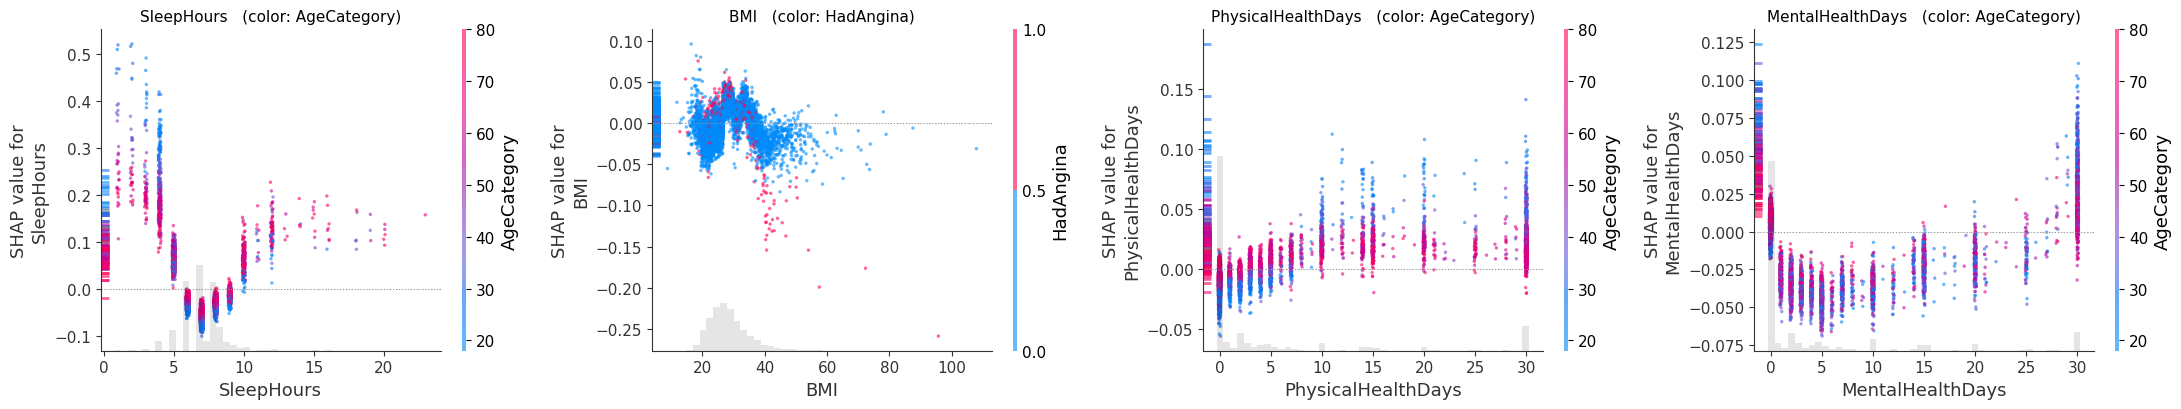

In [14]:
continuous = ["SleepHours", "BMI", "PhysicalHealthDays", "MentalHealthDays"]
dependence_grid(continuous, n_cols=4, filename="shap_dependence_continuous.png", height=4.2)

The continuous features matter much less (ranks 13 to 25), but their shapes are worth knowing:
- **SleepHours** is U-shaped: 4 hours or less adds about +0.2, 11 or more hours about +0.1, and 6 to 8 hours is slightlyyy protective.
- **BMI** is nearly flat -- almost every point is within ±0.05. The model gets that information through diabetes and general health instead.
- **PhysicalHealthDays** had the highest correlation with the target among the numeric columns in the EDA (r = 0.145), but its SHAP effect = small. `GeneralHealth`, `DifficultyWalking` and `disability_count` carry the same information, and the trees used those instead.

### 6. Individual explanations

A waterfall plot starts at the base value (E[f(X)], bottom) and adds 1 feature at a time, biggest contribution first, until it reaches this person's output f(x) at the top. Red bars push predicted risk up, blue bars push it down. The axis is log-odds; the title = gives the predicted probability.

1 person from each cell of the confusion matrix at the operating threshold: the one whose predicted probability is closest to that cell's median, so these are typical cases, not extremes.

In [15]:
LABELS = {
    "Sex": {1: "Male", 0: "Female"},
    "GeneralHealth": {0: "Poor", 1: "Fair", 2: "Good", 3: "Very good", 4: "Excellent"},
    "RemovedTeeth": {0: "None", 1: "1 to 5", 2: "6+, not all", 3: "All"},
    "LastCheckupTime": {0: "< 1 year", 1: "1-2 years", 2: "2-5 years", 3: "5+ years"},
    "SmokerStatus": {0: "Never", 1: "Former", 2: "Current, some days", 3: "Current, every day"},
    "ECigaretteUsage": {0: "Never", 1: "Not now", 2: "Some days", 3: "Every day"},
}
SHORT = {  # long survey answers, shortened for plot labels
    "No, pre-diabetes or borderline diabetes": "Pre-diabetes",
    "Yes, but only during pregnancy (female)": "Only during pregnancy",
    "No, did not receive any tetanus shot in the past 10 years": "No shot in 10 yrs",
    "Yes, received tetanus shot but not sure what type": "Yes, type unknown",
    "Yes, received tetanus shot, but not Tdap": "Yes, not Tdap",
    "Yes, received Tdap": "Yes, Tdap",
    "Tested positive using home test without a health professional": "Yes (home test)",
}


def readable(row):
    # one test row -> "Feature = value" labels people can read
    out = []
    for f in FEATURES:
        v = row[f]
        if pd.isna(v):
            text = "missing"
        elif f in CAT_COLS:
            text = SHORT.get(str(v), str(v))
        elif f in LABELS:
            text = LABELS[f][int(v)]
        elif f in YES_NO:
            text = "Yes" if v == 1 else "No"
        elif f == "AgeCategory":
            text = {18: "18-24", 80: "80+"}.get(int(v), f"{int(v)}-{int(v) + 4}")
        elif f in ("BMI", "WeightInKilograms"):
            text = f"{v:.1f}"
        elif f == "HeightInMeters":
            text = f"{v:.2f}"
        else:
            text = f"{v:g}"
        out.append(f"{f} = {text}")
    return out


y_arr = y_test.to_numpy()
cells = {"True positive": (y_arr == 1) & (test_pred == 1),
         "False positive": (y_arr == 0) & (test_pred == 1),
         "False negative": (y_arr == 1) & (test_pred == 0),
         "True negative": (y_arr == 0) & (test_pred == 0)}

examples = {}
for name, mask in cells.items():
    rows = np.flatnonzero(mask)
    examples[name] = rows[np.argmin(np.abs(p_test[rows] - np.median(p_test[rows])))]

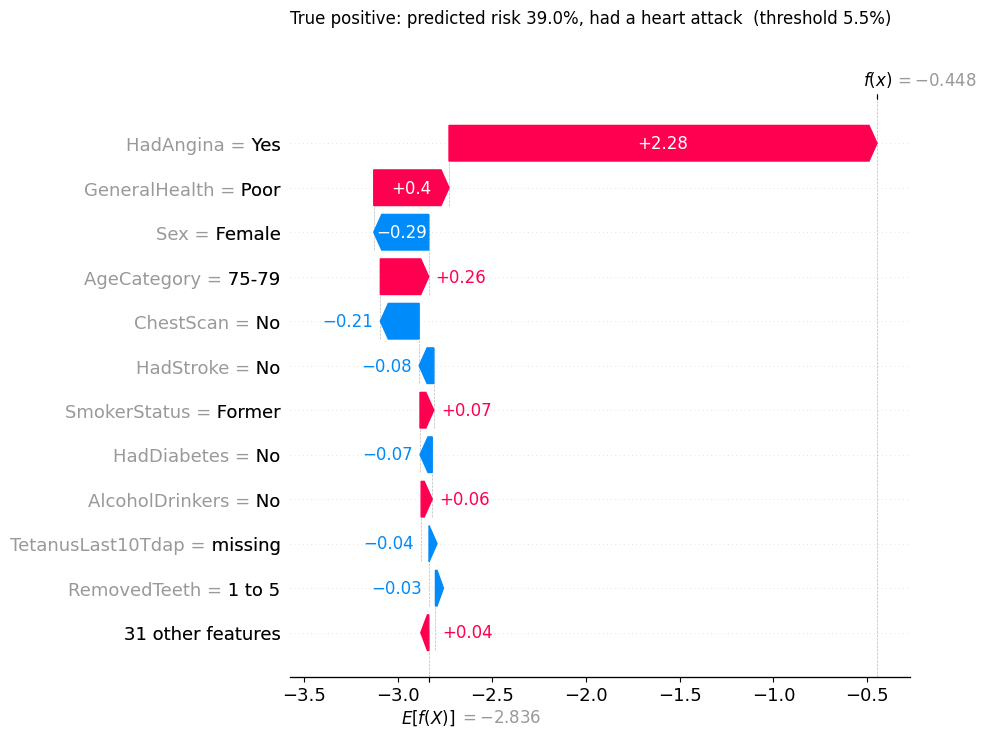

Biggest pushes up: HadAngina +2.28, GeneralHealth +0.40, AgeCategory +0.26
Biggest pushes down: Sex -0.29, ChestScan -0.21, HadStroke -0.08



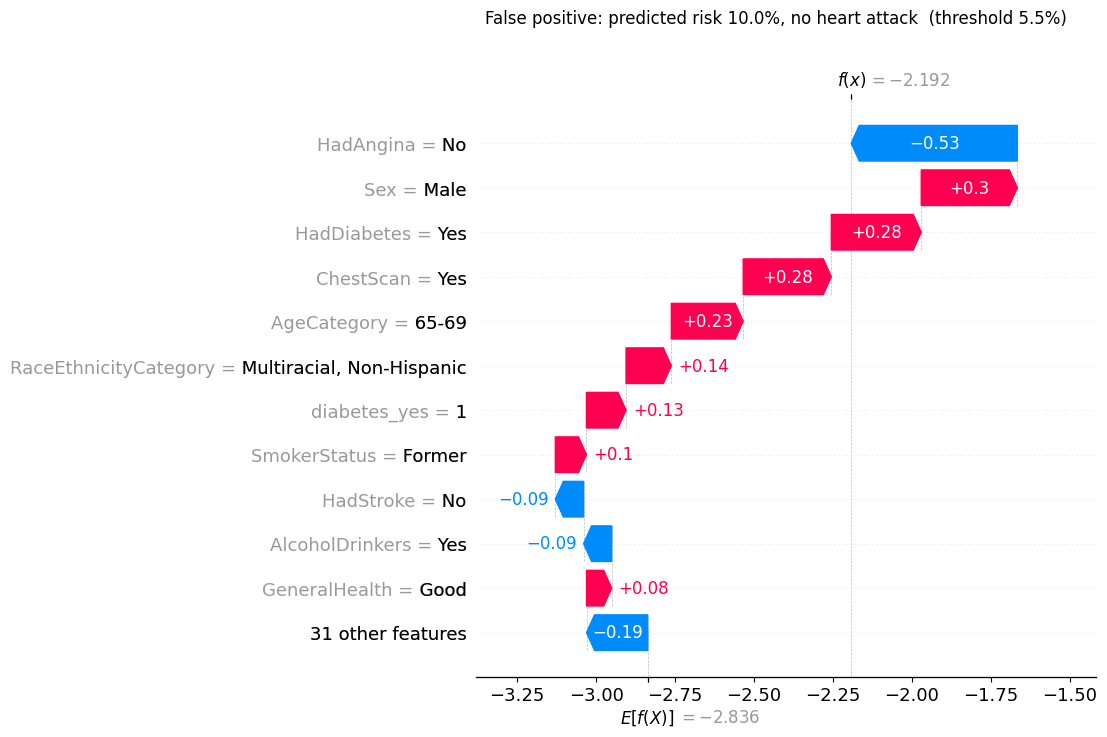

Biggest pushes up: Sex +0.30, HadDiabetes +0.28, ChestScan +0.28
Biggest pushes down: HadAngina -0.53, HadStroke -0.09, AlcoholDrinkers -0.09



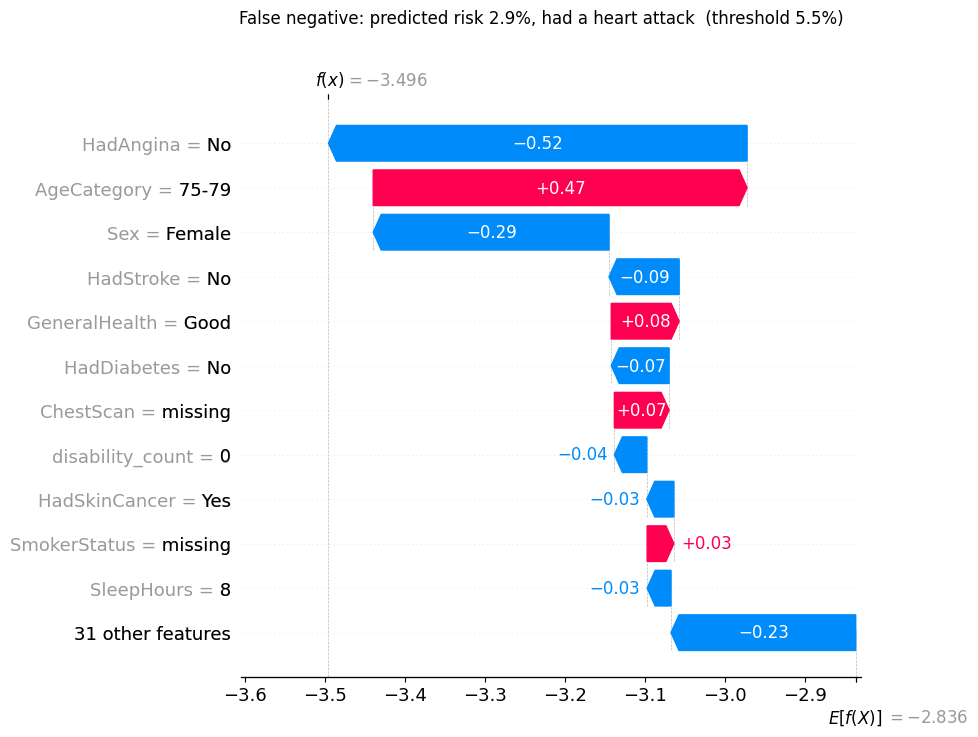

Biggest pushes up: AgeCategory +0.47, GeneralHealth +0.08, ChestScan +0.07
Biggest pushes down: HadAngina -0.52, Sex -0.29, HadStroke -0.09



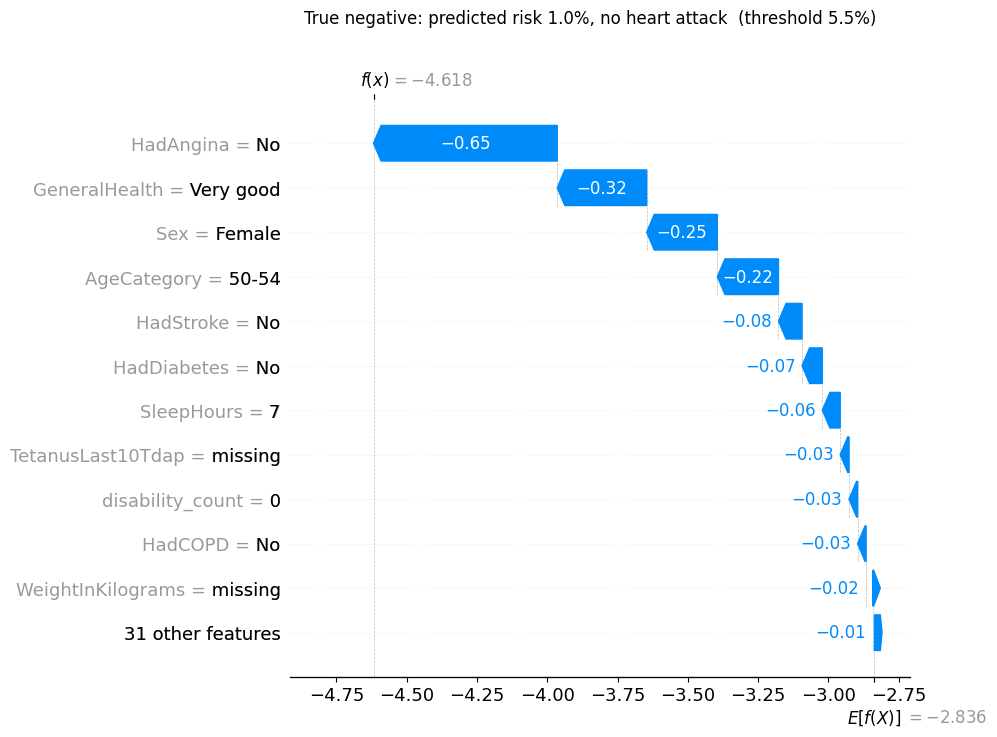

Biggest pushes up: DeafOrHardOfHearing +0.02, BlindOrVisionDifficulty +0.02, SmokerStatus +0.02
Biggest pushes down: HadAngina -0.65, GeneralHealth -0.32, Sex -0.25



In [16]:
def waterfall(i, name):
    case = shap.Explanation(values=shap_values[i], base_values=base_value,
                            feature_names=readable(X_test.iloc[i]))
    shap.plots.waterfall(case, max_display=12, show=False)
    truth = "had a heart attack" if y_arr[i] == 1 else "no heart attack"
    plt.gcf().suptitle(f"{name}: predicted risk {p_test[i]:.1%}, {truth}  (threshold {THRESHOLD:.1%})",
                       fontsize=12, y=1.0)
    plt.savefig(OUT_DIR / f"shap_waterfall_{name.lower().replace(' ', '_')}.png", dpi=200, bbox_inches="tight")
    plt.show()

    contrib = pd.Series(shap_values[i], index=FEATURES)
    up = ", ".join(f"{f} {contrib[f]:+.2f}" for f in contrib.nlargest(3).index)
    down = ", ".join(f"{f} {contrib[f]:+.2f}" for f in contrib.nsmallest(3).index)
    print(f"Biggest pushes up: {up}\nBiggest pushes down: {down}\n")


for name, i in examples.items():
    waterfall(i, name)

4 typical cases at the 80%-recall cutoff (5.5%):
- **True positive** (39.0%): a woman aged 75-79 in poor health who reports angina. Angina adds +2.28, far more than everything else combined (+0.11).
- **False positive** (10.0%): a man aged 65-69 without angina, but with diabetes and a chest scan. Those, plus his age and sex, lift him over the low 5.5% cutoff even though "No" to angina takes away 0.53.
- **False negative** (2.9%): a woman aged 75-79 in good health, with no angina, stroke or diabetes. Her age adds +0.47, but "No" to angina, being female and many small items pull her down to 2.9%.
- **True negative** (1.0%): a woman aged 50-54 in very good health. No angina, very good health, being female and her age all push her prediction down.

#### What the missed cases have in common

The same pattern across the whole test set:

In [17]:
def pct(mask, col, cond):
    return 100 * cond(X_test.loc[mask, col]).mean()


profile = pd.DataFrame({
    name: {"people": int(mask.sum()),
           "mean predicted risk %": 100 * p_test[mask].mean(),
           "report angina %": pct(mask, "HadAngina", lambda s: s == 1),
           "mean age (bracket start)": X_test.loc[mask, "AgeCategory"].mean(),
           "chest scan %": pct(mask, "ChestScan", lambda s: s == 1),
           "male %": pct(mask, "Sex", lambda s: s == 1),
           "fair/poor health %": pct(mask, "GeneralHealth", lambda s: s <= 1),
           "stroke %": pct(mask, "HadStroke", lambda s: s == 1),
           "diabetes %": pct(mask, "diabetes_yes", lambda s: s == 1)}
    for name, mask in cells.items()})
profile.round(1)

,True positive,False positive,False negative,True negative
people,3952.0,15080.0,1070.0,68312.0
mean predicted risk %,36.6,16.8,2.9,1.5
report angina %,61.3,19.2,0.0,0.0
mean age (bracket start),68.1,68.0,60.0,48.6
chest scan %,72.8,73.3,44.3,27.1
male %,65.7,59.5,49.5,43.2
fair/poor health %,51.9,46.4,15.5,9.5
stroke %,23.5,15.8,1.3,0.5
diabetes %,38.6,35.4,14.4,7.2


In [18]:
angina = X_test["HadAngina"].to_numpy()
by_angina = {}
for label, mask in {"reports angina": angina == 1,
                    "no angina": angina == 0,
                    "angina answer missing": np.isnan(angina)}.items():
    yy, pp = y_arr[mask], p_test[mask]
    by_angina[label] = {"people": int(mask.sum()),
                        "heart attack rate %": 100 * yy.mean(),
                        f"recall % ({THRESHOLD_LABEL})": 100 * (pp[yy == 1] >= THRESHOLD).mean(),
                        "recall % (best F1)": 100 * (pp[yy == 1] >= THRESHOLD_BEST_F1).mean(),
                        f"flagged % ({THRESHOLD_LABEL})": 100 * (pp >= THRESHOLD).mean(),
                        "ROC-AUC within group": roc_auc_score(yy, pp),
                        "PR-AUC within group": average_precision_score(yy, pp),
                        "highest predicted risk %": 100 * pp.max()}
display(pd.DataFrame(by_angina).T.round(3))

flagged = p_test >= THRESHOLD
false_pos = flagged & (y_arr == 0)
print(f"At the operating threshold: {np.mean(angina[flagged] == 1):.1%} of flagged people "
      f"and {np.mean(angina[false_pos] == 1):.1%} of false positives report angina")

,people,heart attack rate %,recall % (80% recall),recall % (best F1),flagged % (80% recall),ROC-AUC within group,PR-AUC within group,highest predicted risk %
reports angina,5316.0,45.598,100.000,95.957,100.000,0.657,0.615,87.494
no angina,82355.0,2.856,54.634,3.656,15.773,0.815,0.118,47.077
angina answer missing,743.0,33.109,98.780,87.805,97.712,0.684,0.477,75.573


At the operating threshold: 27.9% of flagged people and 19.2% of false positives report angina


**The angina dependence, and how the threshold changes it.** Our model leans on angina at any cutoff, but how much that costs depends on where the cutoff sits --- At the best-F1 cutoff (0.251) the model works close to an angina rule: it catches 96% of heart attack cases who report angina and under 4% of those who don't. At the team's 80%-recall cutoff (0.055) it catches every case with angina and 55% of cases without. None of the 1,070 cases it still misses reported angina (profile table above).

Inside the no-angina group the model ranks risk reasonably well, = (ROC-AUC 0.82, PR-AUC 0.12, four times the 2.9% base rate). A model trained without angina ranks that group no better (`xgboost_without_angina.ipynb`), so the misses come from the weaker signal in this group, not from the angina feature crowding other features out.

Note what `HadAngina` actually is: the BRFSS question "Ever told you had angina or coronary heart disease?" So the top driver is essentially a dx of the disease that causes heart attacks. At the 80% cutoff most flagged people don't report it (28% do), and 19% of the false positives answered Yes: people with diagnosed heart disease who haven't had a heart attack.

### 7. Age, sex and race/ethnicity (input for Task #4)

SHAP doesn't tell us whether the model is fair, but it does show how much the model uses these attributes directly and in which direction. The tables give, for each group, the avg SHAP value of the attribute itself, next to the observed heart attack rate, the model's average predicted risk, and the share flagged at the operating threshold.

In [19]:
def by_group(feature, groups):
    s = pd.Series(shap_values[:, idx[feature]], index=X_test.index)
    p = pd.Series(p_test, index=X_test.index)
    return pd.DataFrame({"people": groups.value_counts(),
                         f"mean SHAP of {feature}": s.groupby(groups, observed=True).mean(),
                         "observed rate %": 100 * y_test.groupby(groups, observed=True).mean(),
                         "mean predicted risk %": 100 * p.groupby(groups, observed=True).mean(),
                         "flagged %": 100 * (p >= THRESHOLD).groupby(groups, observed=True).mean()}).round(3)


sex = X_test["Sex"].map({1.0: "Male", 0.0: "Female"})
race = X_test["RaceEthnicityCategory"].astype(object).fillna("(missing)")
age_band = pd.cut(X_test["AgeCategory"], [0, 39, 54, 69, 120], labels=["18-39", "40-54", "55-69", "70+"])

display(by_group("Sex", sex))
display(by_group("RaceEthnicityCategory", race))
display(by_group("AgeCategory", age_band))
print("Share of total mean |SHAP|:",
      {f: f"{ranking.loc[f, 'share_%']:.1f}%" for f in ["AgeCategory", "Sex", "RaceEthnicityCategory"]})

,people,mean SHAP of Sex,observed rate %,mean predicted risk %,flagged %
Sex,,,,,
Female,46783,-0.241,4.051,4.217,15.955
Male,41631,0.212,7.511,7.383,27.787


,people,mean SHAP of RaceEthnicityCategory,observed rate %,mean predicted risk %,flagged %
RaceEthnicityCategory,,,,,
(missing),2704,0.005,6.879,6.495,24.556
"Black only, Non-Hispanic",6879,-0.139,4.565,4.796,20.323
Hispanic,8554,0.024,3.998,3.799,14.262
"Multiracial, Non-Hispanic",1912,0.121,5.858,6.063,22.228
"Other race only, Non-Hispanic",4453,0.106,4.065,4.582,17.224
"White only, Non-Hispanic",63912,0.003,6.082,6.096,22.778


,people,mean SHAP of AgeCategory,observed rate %,mean predicted risk %,flagged %
AgeCategory,,,,,
18-39,20592,-1.147,0.694,0.745,1.496
40-54,18310,-0.467,2.430,2.637,7.433
55-69,25458,0.057,6.811,6.682,24.236
70+,22352,0.405,11.730,11.828,49.239


Share of total mean |SHAP|: {'AgeCategory': '16.4%', 'Sex': '7.4%', 'RaceEthnicityCategory': '0.8%'}


- **Age/ sex are major drivers** (16.4% and 7.4% of the total). Both are well-known risk factors, so that isn't a red flag by itself -- It mean the model flags fewer women than men (16.0% vs 27.8%) and few people under 40 (1.5%). Their observed rates are lower too (4.1% vs 7.5%, and 0.7% under 40), so Task #4 Nov should check whether recall holds up within these groups.
- **Race/ethnicity is used lightly but not zero** (0.8% of the total). The race feature itself lowers the prediction for Black respondents by 0.14 log-odds on average, and raises it by about 0.1 for multiracial and "other race" respondents. These are adjustments on top of everything else the model knows about each person.
- The model's avg predicted risk is close to the observed rate in every group (e.g. 4.8% vs 4.6% for Black respondents, 6.1% vs 6.1% for White respondents), so it's calibrated on average. Whether recall and false positive rate also hold up within each group is the Task #4 question.
- Dropping the race column wouldn't necessarily remove these effects, because other features can act as proxies.

### 8. Findings/Results

Numbers are from the run saved in this notebook (XGBoost 3.2). A run with another XGBoost version moves them slightly, not the order.

**Top drivers of predicted risk** (by mean |SHAP|, log-odds; +0.7 ≈ double the odds)

| # | Feature | Share | Effect |
|---|---|---|---|
| 1 | Angina or coronary heart disease (`HadAngina`) | 23.6% | Yes: +2.1 (about 8x the odds). No: -0.6. Missing: +1.7 |
| 2 | Age (`AgeCategory`) | 16.4% | Rises steadily, from -1.3 (18-24) to +0.5 (80+) |
| 3 | Chest scan (`ChestScan`) | 10.2% | Yes: +0.3. No: -0.4 |
| 4 | Sex | 7.4% | Male: +0.2. Female: -0.2. Gap grows with age |
| 5 | General health | 7.2% | Poor/Fair: +0.3 to +0.4. Very good/Excellent: -0.3 to -0.4 |
| 6 | Tooth loss (`RemovedTeeth`) | 4.5% | None: -0.2. All: +0.35 |
| 7 | Stroke (`HadStroke`) | 4.0% | Yes: +0.9, but only 4% report one |
| 8 | Smoking (`SmokerStatus`) | 3.2% | Never: -0.1. Current: +0.15 to +0.17 |
| 9 | Diabetes (`HadDiabetes`) | 3.0% (3.8% with `diabetes_yes`) | Yes: +0.26, or +0.33 counting `diabetes_yes` |
| 10 | Alcohol (`AlcoholDrinkers`) | 2.0% | Drinkers: -0.08. Non-drinkers: +0.06 |

**The big picture**
- Model mostly recognizes people who already report heart-related conditions (angina, stroke), older people and men, plus signs of regular contact with doctors (chest scans, checkups). CV hx and age make up half of what it uses. Lifestyle and body size make up 5%.
- How much the angina dependence matters depends on the cutoff -- At the best-F1 cutoff the model is close to an angina rule (recall 96% with angina, under 4% without). At the team's 80%-recall cutoff it catches every case with angina and 55% of cases without, at 21% precision with 21.5% of people flagged.
- We should keep angina: a model trained without it drops from PR-AUC 0.434 to 0.262 and ranks people without angina no better (ROC-AUC 0.815 either way; `xgboost_without_angina.ipynb`).

**Caveats for the report**
- SHAP explains the model, not the biology. These are associations in survey data.
- The target is a *past* heart attack. `HadAngina` means "ever told you had angina or coronary heart disease", the same disease that causes heart attacks, and chest scans and recent checkups often happen *because of* heart disease. These features describe people who are already in care, which is why they predict a past heart attack so well. They are not causes, and they say little about future risk.
- Drinkers getting lower predicted risk most likely reflects people who stopped drinking after getting sick (the "sick quitter" effect), not a protective effect of alcohol.
- Missing answers carry signal: people who skipped the angina question had a 33% heart attack rate, and the model treats a skipped answer almost like a "Yes".
- All answers are self-reported and from one survey year (2022).